# One set of Finance numbers everyone can trust: analysis notebook

**Context.** Sekoia's Finance Data Analyst job post asks to map Finance data, settle definitions (ARR, NRR, headcount, payroll cost,
COGS, cash, expenses), reconcile sources and explain the gaps. Sekoia's internal numbers are not public, so this notebook works on a
**fictional 180-person cybersecurity SaaS scale-up** (SIMULATED, 24 months, Dec 2024 - Nov 2026) built on **real public inputs**
(cloud unit prices, ECB rates, French holidays, SEC 10-K benchmarks).

**Order**: map of systems -> definitions -> reconciliations and cascades -> the 8 planted problems found back (the March false signal is
**not** retained) -> ARR bridge and NRR -> unit economics and retention cost -> gross margin vs public benchmarks -> budget vs actual and
cash -> backlog.

Run first: `python src/fetch_public.py`, `python src/simulate_company.py`, `python src/run_sql.py`, `python src/run_tests.py`.

In [1]:
import json, duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import os; os.chdir(ROOT)  # the warehouse views read data/... with relative paths
con = duckdb.connect(str(ROOT / 'data' / 'finance.duckdb'), read_only=True)
q = lambda sql: con.sql(sql).df()
H = json.loads((ROOT / 'data' / 'marts' / 'headline.json').read_text(encoding='utf-8'))
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'font.family': 'Segoe UI', 'axes.spines.top': False, 'axes.spines.right': False, 'figure.figsize': (9, 3.4)})

## 1. Map of the systems
Twelve sources (full map, owners and lineage in `docs/DATA_MAP.md`). Row counts of each simulated export:

In [2]:
tables = ['stg_crm_companies','stg_crm_deals','stg_billing_accounts','stg_billing_contracts','stg_billing_invoices','stg_gl_entries',
          'stg_cash_transactions','stg_budget_2026','stg_hris_employees','stg_payroll_monthly','stg_expenses','stg_ats_requisitions',
          'stg_cloud_costs_focus','stg_customer_usage']
pd.DataFrame([(t, con.sql(f'select count(*) from {t}').fetchone()[0]) for t in tables], columns=['staging view', 'rows'])

,staging view,rows
0,stg_crm_companies,443
1,stg_crm_deals,1347
2,stg_billing_accounts,455
3,stg_billing_contracts,1283
4,stg_billing_invoices,2074
5,stg_gl_entries,7341
6,stg_cash_transactions,1594
7,stg_budget_2026,240
8,stg_hris_employees,240
9,stg_payroll_monthly,3801


## 2. Definitions retained
- **ARR** = annual value of recurring contract lines active on the last day of the month, from **billing contracts**, on one customer key.
- **NRR / GRR (12 months)** = ARR today of last year's customers / their ARR then (GRR caps each customer at its old ARR).
- **Headcount** = employment contracts at month end, interns excluded; **FTE** = contractual working time; **paid persons** = payslips.
- **COGS** = production hosting + AI inference + support and SOC operations payroll + production tools.
Full list with traps: `docs/METRIC_DEFINITIONS.md`.

## 3. Reconciliations: status of every check over 24 months

In [3]:
q("select check_name, status, count(*) as months from fct_reconciliations group by all order by check_name, status")

,check_name,status,months
0,Bank vs ledger cash,OK,22
1,Bank vs ledger cash,WARN,2
2,Billing vs ledger subscription revenue,EXPLAINED,2
3,Billing vs ledger subscription revenue,OK,22
4,CRM vs billing ARR,EXPLAINED,24
5,Cloud bills vs ledger hosting,EXPLAINED,2
6,Cloud bills vs ledger hosting,OK,22
7,HRIS vs payroll headcount,EXPLAINED,6
8,HRIS vs payroll headcount,OK,18
9,Payroll register vs ledger payroll cost,EXPLAINED,2


### 3.1 Why ARR has three values: the CRM -> billing cascade

In [4]:
q("select strftime(month, '%Y-%m') as month, step, round(amount_eur) as eur from fct_arr_waterfall order by month, step_order")

,month,step,eur
0,2026-03,"CRM closed-won ARR, amounts as typed","28,660,000.00"
1,2026-03,Multi-year deals typed at total contract value,"-6,164,600.00"
2,2026-03,CRM amount before the last discount,"-116,700.00"
3,2026-03,Closed-won deals with no billing contract,-0.00
4,2026-03,Unexplained residual,0.00
5,2026-03,"Billing ARR, contracts (clean) = reference","22,378,700.00"
6,2026-03,Contracts closed early by the billing migratio...,"-2,487,200.00"
7,2026-03,"Billing ARR, raw export","19,891,500.00"
8,2026-03,Ledger run-rate (subscription revenue x 12),"22,378,700.00"
9,2026-11,"CRM closed-won ARR, amounts as typed","32,572,900.00"


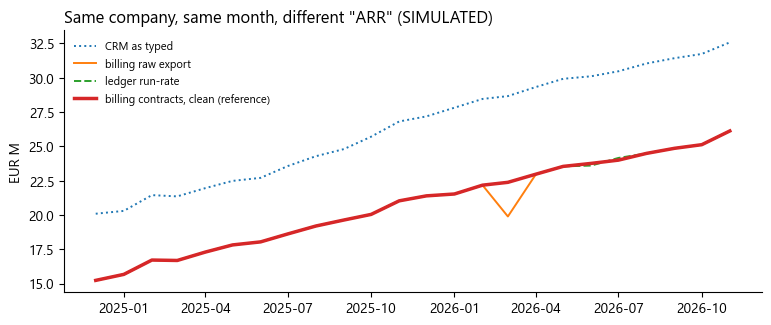

In [5]:
t = q("select * from fct_arr_three_values order by month")
fig, ax = plt.subplots()
for col, lab, st in [('arr_crm_as_typed','CRM as typed',':'), ('arr_billing_raw','billing raw export','-'), ('arr_gl_runrate','ledger run-rate','--'), ('arr_billing_clean','billing contracts, clean (reference)','-')]:
    ax.plot(t.month, t[col] / 1e6, st, label=lab, lw=2.5 if 'clean' in col else 1.4)
ax.set_ylabel('EUR M'); ax.legend(frameon=False, fontsize=8); ax.set_title('Same company, same month, different "ARR" (SIMULATED)', loc='left'); plt.show()

## 4. The eight planted problems, found back from the data

**Event 1 - false signal (March 2026).** Raw billing ARR drops, then comes back in April. The gap is one day on 40 renewal lines; the ledger does not move. **Not escalated.**

In [6]:
q('''select strftime(month, '%Y-%m') as month, round(arr_billing_raw) as raw, round(arr_billing_clean) as clean, round(arr_gl_runrate) as ledger
     from fct_arr_three_values where month between '2026-02-01' and '2026-04-01' order by month''')

,month,raw,clean,ledger
0,2026-02,"22,172,200.00","22,172,200.00","22,172,200.00"
1,2026-03,"19,891,500.00","22,378,700.00","22,378,700.00"
2,2026-04,"22,974,100.00","22,974,100.00","22,974,100.00"


In [7]:
q('''select date_diff('day', end_date, next_start) - 1 as gap_days, count(*) as lines, round(sum(annual_value_eur)) as arr
     from int_contracts_clean where next_start is not null and date_diff('day', end_date, next_start) > 1 group by 1''')

,gap_days,lines,arr
0,214,2,"39,700.00"
1,1,40,"2,487,200.00"
2,458,1,"9,100.00"
3,273,1,"10,000.00"
4,639,1,"1,300.00"
5,245,1,"13,600.00"
6,181,2,"12,900.00"
7,242,1,"2,000.00"
8,487,1,"21,800.00"
9,275,1,"1,500.00"


In [8]:
q('''select strftime(month, '%Y-%m') as month, basis, round(nrr*100, 1) as nrr_pct from fct_nrr_cohort
     where cohort = 'All' and month between '2026-02-01' and '2026-04-01' order by basis, month''')

,month,basis,nrr_pct
0,2026-02,billing raw (by account),103.20
1,2026-03,billing raw (by account),91.00
2,2026-04,billing raw (by account),101.60
3,2026-02,contracts (clean),107.10
4,2026-03,contracts (clean),108.20
5,2026-04,contracts (clean),108.60


**Event 2 - duplicate customers.** Billing accounts sharing a VAT number, created at a renewal with the name typed again and no CRM id.

In [9]:
q('''select customer_key, billing_account_id, account_name, crm_company_id_on_account, names_agree
     from int_customer_xref where accounts_with_same_vat > 1 order by customer_key, billing_account_id limit 8''')

,customer_key,billing_account_id,account_name,crm_company_id_on_account,names_agree
0,C0006,ACC-1005,Ekovo Transports SAS,HS560035,True
1,C0006,ACC-5004,EKOVO TRANSPORTS S.A.S.,None,True
2,C0070,ACC-1069,Zenven Sante SAS,HS560483,True
3,C0070,ACC-5002,ZENVEN S.A.NTE S.A.S.,None,True
4,C0072,ACC-1071,Miquar Bank SAS,HS560497,True
5,C0072,ACC-5000,MIQUAR BANK S.A.S.,None,True
6,C0122,ACC-1121,Luton Group SAS,HS560847,True
7,C0122,ACC-5001,LUTON GROUP S.A.S.,None,True


In [10]:
print(f"{H['billing_accounts']} billing accounts for {H['customers_all_time']} customers; NRR Nov 2026: raw {H['nrr_raw_nov26']:.1%} vs clean {H['nrr_clean_nov26']:.1%}")

455 billing accounts for 443 customers; NRR Nov 2026: raw 104.6% vs clean 108.3%


**Event 3 - multi-year deals typed at total contract value in the CRM.** The ratio CRM amount / billed annual value equals the term in years.

In [11]:
q('''select contract_term_months, count(*) as deals, round(avg(crm_amount_eur / billing_acv_eur), 2) as crm_over_billing
     from int_crm_deal_lines where contract_id is not null and deal_type <> 'Upsell' group by 1 order by 1''')

,contract_term_months,deals,crm_over_billing
0,12,1071,1.00
1,24,27,2.00
2,36,26,3.02


**Event 4 - three headcounts, all right by their own definition** (aggregated; no group under 5 people).

In [12]:
q('''select strftime(month, '%Y-%m') as month, hris_active_records, headcount_reported, fte_reported, paid_persons, interns, apprentices,
            final_settlements, suspected_leavers
     from fct_headcount_payroll where department = 'All departments' and month in ('2024-12-01', '2026-06-01', '2026-11-01')''')

,month,hris_active_records,headcount_reported,fte_reported,paid_persons,interns,apprentices,final_settlements,suspected_leavers
0,2024-12,130,126,125.20,131,4,5,0,0
1,2026-06,172,167,166.00,172,4,11,1,1
2,2026-11,187,181,179.80,187,4,12,0,2


**Event 5 - the dollar in COGS.** AWS bills in USD: last three months vs the three before, split into volume, price and FX.

In [13]:
q('''select comparison, round(base_eur) as base, round(volume_effect_eur) as volume, round(price_effect_eur) as price,
            round(fx_effect_eur) as fx, round(actual_eur) as actual, round(fx_effect_eur / change_eur, 3) as fx_share,
            round(base_usd_per_eur, 4) as usd_rate_before, round(actual_usd_per_eur, 4) as usd_rate_after
     from fct_cloud_price_volume_fx where comparison like 'Sep%' ''')

,comparison,base,volume,price,fx,actual,fx_share,usd_rate_before,usd_rate_after
0,Sep-Nov 2026 vs Jun-Aug 2026,"622,827.00","17,631.00",-0.00,"11,754.00","652,213.00",0.40,1.15,1.13


**Event 6 - retention that costs money.** Three flat-fee customers keep logs 365 days instead of 120 since July 2025, without repricing.

In [14]:
u = q('''select strftime(month, '%Y-%m') as month, customer_key, retention_days, stored_tb, round(revenue_month_eur) as revenue,
               round(storage_cost_eur + search_compute_cost_eur) as retention_cost, round(gross_margin_pct, 3) as gm
        from fct_unit_economics where customer_key in (select customer_key from fct_unit_economics
             where month = '2026-11-01' and gross_margin_eur < 0) and month in ('2025-06-01', '2025-07-01', '2026-11-01')
        order by customer_key, month''')
u

,month,customer_key,retention_days,stored_tb,revenue,retention_cost,gm
0,2025-06,C0004,120,81.20,"7,767.00","2,765.00",0.42
1,2025-07,C0004,365,253.50,"7,767.00","8,539.00",-0.32
2,2026-11,C0004,365,283.10,"9,458.00","9,836.00",-0.31
3,2025-06,C0047,120,77.60,"8,883.00","2,643.00",0.51
4,2025-07,C0047,365,233.10,"8,883.00","7,853.00",-0.07
5,2026-11,C0047,365,266.60,"9,475.00","9,264.00",-0.16
6,2025-06,C0253,120,95.00,"7,133.00","3,234.00",0.29
7,2025-07,C0253,365,310.00,"7,133.00","10,442.00",-0.72
8,2026-11,C0253,365,345.70,"7,717.00","12,013.00",-0.81


**Event 7 - AI costs and untagged resources.** A new cost line appears with the AI feature (Oct 2025); resources created for it carry no tag.

In [15]:
q('''select strftime(month, '%Y-%m') as month, round(sum(cost_eur) filter (where product_allocated = 'ai')) as ai_eur,
            round(avg(is_untagged::int), 3) as untagged_resource_share,
            round(sum(cost_eur) filter (where is_untagged) / sum(cost_eur), 3) as untagged_cost_share
     from int_cloud_costs_eur where month >= '2025-09-01' group by 1 order by 1''').tail(4)

,month,ai_eur,untagged_resource_share,untagged_cost_share
11,2026-08,"15,907.00",0.18,0.06
12,2026-09,"15,471.00",0.18,0.06
13,2026-10,"16,289.00",0.18,0.06
14,2026-11,"17,132.00",0.18,0.07


**Event 8 - close timing.** Sales kick-off at the end of January 2026; expense reports are approved in February.

In [16]:
q('''select strftime(month, '%Y-%m') as month, round(budget_eur) as budget, round(actual_eur) as actual, round(variance_pct, 3) as variance_pct
     from fct_budget_vs_actual where budget_line = 'Travel and expenses' and month <= '2026-03-01' order by month''')

,month,budget,actual,variance_pct
0,2026-01,"124,562.00","63,819.00",-0.49
1,2026-02,"62,359.00","124,630.00",1.00
2,2026-03,"62,359.00","74,730.00",0.20


In [17]:
q('''select strftime(date_trunc('month', expense_date), '%Y-%m') as incurred, strftime(date_trunc('month', approved_date), '%Y-%m') as booked,
            count(*) as lines, round(sum(amount_eur)) as eur from stg_expenses where trip_tag = 'SKO-2026' group by all''')

,incurred,booked,lines,eur
0,2026-01,2026-02,171,"62,203.00"


## 5. Growth that holds: ARR bridge and NRR (reference basis)

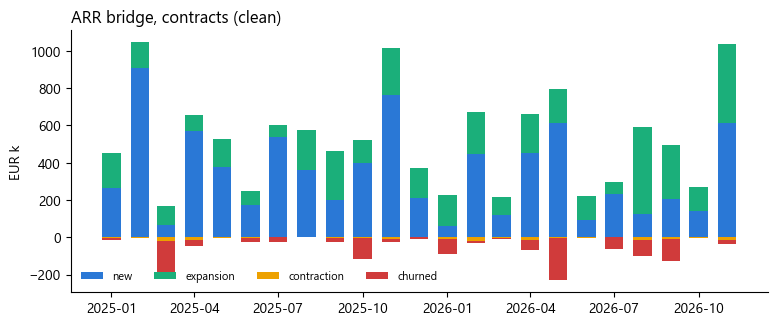

ARR 15.2M (Dec 2024) -> 26.1M (Nov 2026); +24% year on year


In [18]:
b = q("select * from fct_arr_monthly where basis = 'contracts (clean)' order by month")
fig, ax = plt.subplots()
for col, c in [('new_arr','#2A78D6'), ('expansion_arr','#1BAF7A'), ('contraction_arr','#EDA100'), ('churned_arr','#D03B3B')]:
    ax.bar(b.month, b[col] / 1e3, width=20, label=col.replace('_arr',''), color=c, bottom=0 if col in ('new_arr','contraction_arr') else (b.new_arr / 1e3 if col == 'expansion_arr' else b.contraction_arr / 1e3))
ax.set_ylabel('EUR k'); ax.legend(frameon=False, ncol=4, fontsize=8); ax.set_title('ARR bridge, contracts (clean)', loc='left'); plt.show()
print(f"ARR {H['arr_dec24']/1e6:.1f}M (Dec 2024) -> {H['arr_nov26']/1e6:.1f}M (Nov 2026); +{H['arr_growth_yoy']:.0%} year on year")

In [19]:
q("select cohort, customers_base, round(nrr*100,1) as nrr, round(grr*100,1) as grr from fct_nrr_cohort where basis = 'contracts (clean)' and month = '2026-11-01' order by cohort")

,cohort,customers_base,nrr,grr
0,2022,33,103.30,95.10
1,2023,96,111.60,96.10
2,2024,132,106.20,96.20
3,2025,82,109.00,97.60
4,All,343,108.30,96.40


## 6. What a customer really costs: unit economics and retention

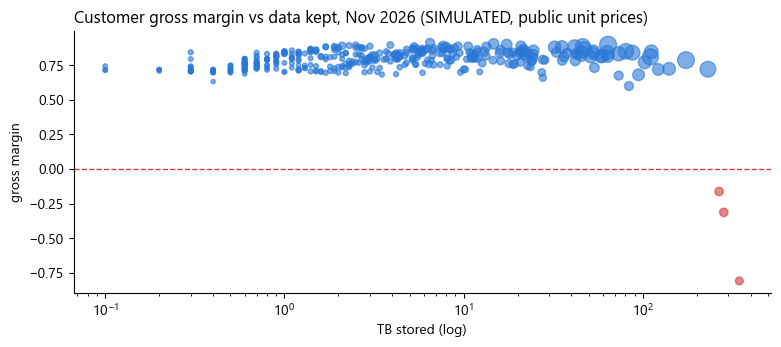

,segment,customers,revenue,cogs,gm
0,Enterprise,48,"644,825.00","143,743.00",0.78
1,MSSP,34,"685,192.00","133,130.00",0.81
2,Mid-market,138,"592,517.00","104,961.00",0.82
3,SMB,182,"254,167.00","49,405.00",0.81


In [20]:
ue = q("select * from fct_unit_economics where month = '2026-11-01'")
fig, ax = plt.subplots()
ax.scatter(ue.stored_tb, ue.gross_margin_pct, s=8 + ue.arr_eur / 4000, c=['#D03B3B' if g < 0 else '#2A78D6' for g in ue.gross_margin_eur], alpha=0.6)
ax.set_xscale('log'); ax.axhline(0, color='#D03B3B', ls='--', lw=1); ax.set_xlabel('TB stored (log)'); ax.set_ylabel('gross margin')
ax.set_title('Customer gross margin vs data kept, Nov 2026 (SIMULATED, public unit prices)', loc='left'); plt.show()
q("select segment, count(*) as customers, round(sum(revenue_month_eur)) as revenue, round(sum(cogs_eur)) as cogs, round(1 - sum(cogs_eur)/sum(revenue_month_eur), 3) as gm from fct_unit_economics where month = '2026-11-01' group by 1 order by 1")

## 7. Gross margin vs public benchmarks (PUBLIC DATA: SEC 10-K)

In [21]:
display(q("select strftime(month, '%Y-%m') as month, round(gross_margin_pct, 3) as gm, round(cloud_pct_revenue, 3) as cloud_pct from fct_gross_margin where month in ('2025-01-01','2025-12-01','2026-11-01')"))
q("select company, period_end, round(gross_margin, 3) as gm, round(deferred_rev_pct_revenue, 2) as deferred_rev_pct, round(rnd_pct_revenue, 2) as rnd, round(sm_pct_revenue, 2) as sm from fct_public_benchmarks qualify row_number() over (partition by company order by period_end desc) = 1")

,month,gm,cloud_pct
0,2025-01,0.81,0.10
1,2025-12,0.81,0.11
2,2026-11,0.81,0.11


,company,period_end,gm,deferred_rev_pct,rnd,sm
0,CrowdStrike,2026-01-31,0.75,0.99,0.29,0.38
1,Rapid7,2025-12-31,0.70,0.56,0.22,0.37
2,SentinelOne,2026-01-31,0.74,0.63,0.32,0.52
3,Tenable,2025-12-31,0.78,0.90,0.22,0.42


Reading: the simulated margin (~80%) sits above the listed vendors (70-78%) mainly because its COGS leaves out customer success and
managed services: the definition moves the number by several points, which is why it is written down once.

## 8. Budget vs actual and cash

In [22]:
q('''select line_group, budget_line, round(sum(budget_eur)) as budget, round(sum(actual_eur)) as actual,
            round(sum(variance_eur)) as variance, round(sum(variance_eur)/sum(budget_eur), 3) as variance_pct
     from fct_budget_vs_actual group by all order by abs(sum(variance_eur)) desc''').head(8)

,line_group,budget_line,budget,actual,variance,variance_pct
0,Revenue,SaaS subscriptions,"22,344,809.00","21,744,358.00","-600,451.00",-0.03
1,Payroll,Payroll - Sales,"2,943,961.00","2,592,347.00","-351,614.00",-0.12
2,Revenue,Professional services,"660,000.00","360,000.00","-300,000.00",-0.46
3,Opex,Marketing and events,"4,026,000.00","3,858,992.00","-167,008.00",-0.04
4,Payroll,Payroll - SOC Operations & Support,"1,696,198.00","1,553,715.00","-142,483.00",-0.08
5,Payroll,Payroll - Customer Success,"933,293.00","1,068,709.00","135,416.00",0.14
6,Payroll,Payroll - G&A,"1,505,769.00","1,613,893.00","108,124.00",0.07
7,COGS,Cloud hosting - AWS,"2,138,255.00","2,214,876.00","76,621.00",0.04


In [23]:
q("select comparison, round(sum(change_eur)) as change, round(sum(volume_effect_eur)) as volume, round(sum(price_effect_eur)) as price, round(sum(fx_effect_eur)) as fx from fct_cloud_price_volume_fx group by 1")

,comparison,change,volume,price,fx
0,actual vs budget,"76,621.00","-77,136.00","121,242.00","32,512.00"
1,Sep-Nov 2026 vs Jun-Aug 2026,"29,385.00","17,631.00",-0.00,"11,754.00"


In [24]:
q("select strftime(month, '%Y-%m') as month, round(closing_cash) as cash, round(operating_cash_flow) as ocf, round(bank_vs_gl_diff, 2) as bank_vs_gl from fct_cash where month >= '2026-06-01'")

,month,cash,ocf,bank_vs_gl
0,2026-06,"22,881,309.00","-188,802.00",0.00
1,2026-07,"22,770,416.00","-110,892.00",0.00
2,2026-08,"22,678,010.00","-92,406.00",0.00
3,2026-09,"23,009,120.00","331,109.00",0.00
4,2026-10,"23,635,169.00","626,049.00","-1,840.00"
5,2026-11,"22,968,694.00","-666,474.00","-1,840.00"


## 9. Backlog (summary, full list in `docs/DATA_NEEDS_BACKLOG.md`)
1. One customer key across CRM, billing and usage (VAT number unique in billing).
2. Annual value field in the CRM, mandatory at closed-won.
3. ARR / NRR / GRR from contracts in Metabase, with the gap rule and the tests.
4. Monthly reconciliation pack at D+2.
5. Tagging policy and allocation rule for cloud and AI costs.
6. Cost to serve per customer, monthly; flag retention above contract before renewal.

In [25]:
con.close()